# Uncertainty Quantification and Sensitivity Analysis for the Electrical Impedance Spectroscopy of Changes to Intercellular Junctions Induced by Cold Atmospheric Plasma

__Jie Zhuang__, Suzhou Institute of Biomedical Engineering and Technology, Chinese Academy of Sciences, Suzhou, China; School of Biomedical Engineering (Suzhou), Division of Life Sciences and Medicine, University of Science and Technology of China, Hefei, China

__Cheng Zhu__, Suzhou Institute of Biomedical Engineering and Technology, Chinese Academy of Sciences, Suzhou, China; School of Biomedical Engineering (Suzhou), Division of Life Sciences and Medicine, University of Science and Technology of China, Hefei, China

__Rui Han__, Suzhou Institute of Biomedical Engineering and Technology, Chinese Academy of Sciences, Suzhou, China; School of Biomedical Engineering (Suzhou), Division of Life Sciences and Medicine, University of Science and Technology of China, Hefei, China

__Anna Steuer__, Leibniz Institute for Plasma Science and Technology (INP), Greifswald, Germany

__Juergen F. Kolb__, Leibniz Institute for Plasma Science and Technology (INP), Greifswald, Germany

__Fukun Shi__, Suzhou Institute of Biomedical Engineering and Technology, Chinese Academy of Sciences, Suzhou, China

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about 20 seconds.

In [1]:
%matplotlib inline
import time
from math import erfc, sqrt

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import cole_model as cm
from generate_data import OMEGA, K

SEED = 5861                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$R_\infty$', r'$R_0$', r'$\alpha$', r'$\tau$']


def k_of(w):
    """Column of the angular frequency w (rad/s) in OMEGA."""
    k = int(np.argmin(np.abs(np.log(OMEGA / w))))
    assert np.isclose(OMEGA[k], w, rtol=1e-4), w
    return k

### Summary

Zhuang et al. [[1]][R1] describe the impedance of a cell monolayer by a Cole-Cole model with four uncertain parameters (the resistances $R_0$ and $R_\infty$, the dispersion factor $\alpha$ and the time constant $\tau$) and study, by polynomial chaos and Sobol' indices, how they drive the real and imaginary parts of the impedance between 1 and $10^7$ (rad/s). We give the four parameters lognormal distributions with the means and standard deviations of the paper's Table 1 and keep only the physical range $\alpha < 1$, **which leaves $\alpha$ with mean 0.657 and standard deviation 0.158 rather than Table 1's 0.7 and 0.21**, and compute active subspaces of $\mathrm{Re}\,Z$ and $\mathrm{Im}\,Z$ from 1022 samples with exact gradients at 31 frequencies. The structure depends strongly on frequency: $\mathrm{Im}\,Z$ at its peak ($\omega = 2\times10^5$) is nearly one-dimensional ($\lambda_1/\lambda_2 = 138$, with $R_0$ and $\alpha$ in equal parts; **the size of this gap is set by the upper tail of $\alpha$**: 155 with the cut at $\alpha < 0.8$, 112 at $\alpha < 1.2$, 17.1 with no cut), $\mathrm{Re}\,Z$ below $10^3$ is $R_0$ alone, and $\mathrm{Re}\,Z$ at $2\times10^6$, the paper's boundary between low and high frequencies, has a weaker gap ($\lambda_1/\lambda_2 = 16$) along a direction that mixes $\alpha$, $R_\infty$ and $R_0$. Monte Carlo under the paper's own Gaussians reproduces its mean impedance curves but **not its finding that $\tau$ is negligible**: the first-order Sobol' index of $\tau$ reaches 0.20.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine [[3]][R3], [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The paper (Sec. 3.3, Eq. 1, p. 11) fits measured spectra with two Cole terms in series, one for electrode polarization and one for the cell monolayer:

$$
Z = Z_{ep} + Z_{cells} = \left[R_{\infty,ep} + \frac{R_{0,ep} - R_{\infty,ep}}{1 + (i\omega\tau_{ep})^{\alpha_{ep}}}\right] + \left[R_\infty + \frac{R_0 - R_\infty}{1 + (i\omega\tau)^{\alpha}}\right].
$$

Its uncertainty and sensitivity study (Sec. 2.1, Figs. 1–3) is on the four cell-monolayer parameters, and it gives no values for the electrode term, so the model here is the second bracket,

$$
Z(\omega;\mathbf x) = R_\infty + \frac{R_0 - R_\infty}{1 + (i\omega\tau)^{\alpha}},\qquad \mathbf x = (R_\infty, R_0, \alpha, \tau),
$$

with $(i\omega\tau)^\alpha = (\omega\tau)^\alpha e^{i\alpha\pi/2}$. $R_\infty$ and $R_0$ are the resistances at infinite and very low frequency, $\alpha$ the dispersion factor ($0<\alpha<1$, p. 11) and $\tau$ the characteristic time constant. `cole_model.py` evaluates $Z$ and its exact gradient in closed form.

**Quantities of interest.** $\mathrm{Re}\,Z(\omega)$ and $\mathrm{Im}\,Z(\omega)$ in $\Omega$ (the paper analyses these two, p. 4), each a scalar at a fixed $\omega$. The data hold both at 31 angular frequencies, $\omega = 10^{k/4}$ rad/s ($k = 0,\dots,28$) plus $2\times10^5$ and $2\times10^6$. The main sections use $\mathrm{Im}\,Z$ at $\omega = 2\times10^5$, where the paper puts the peak of the imaginary part (p. 3), and $\mathrm{Re}\,Z$ at $\omega = 2\times10^6$, which the paper calls the boundary between low and high frequencies (p. 5); a later section shows how the structure changes over the whole range.

**Frequency axis.** The paper's figures label their axis "ω Hz" and its text speaks of "200 kHz" and "2 MHz". With $\tau = 5\,\mu$s, the imaginary part of the Cole term peaks at $\omega\tau = 1$, i.e. $\omega = 2\times10^5$ rad/s ($f = \omega/2\pi = 32$ kHz). The paper puts the peak at "200 kHz" (p. 3), and its Fig. 1b shows it at about $1.5\times10^5$ on its axis, so its axis is $\omega$ in rad/s, the variable of Eq. (1), and we use the paper's axis values as $\omega$. (Had the axis been $f$ with $\omega = 2\pi f$, the peak would sit at $3.2\times10^4$ on it; the comparison section checks this.)

**Inputs.** Table 1 (p. 4) gives each parameter a Gaussian distribution with a mean and a standard deviation ("Sigma"); every standard deviation is 30 % of its mean. It states no truncation. Untruncated, the Gaussians give $\alpha \ge 1$ with probability 7.7 % (outside the physical range $0<\alpha<1$) and $\tau \le 0$, where the model is not defined, with probability $4.3\times10^{-4}$. A Gaussian $\tau$ also puts mass near $\tau = 0$, where the gradient blows up: $\partial Z/\partial\tau \propto \tau^{\alpha-1}$. We therefore use, for all four inputs, **lognormal distributions with the means and standard deviations of Table 1**, $\ln x_j \sim N(\mu_j, \sigma_j^2)$ with $\sigma_j^2 = \ln(1 + 0.3^2)$ and $\mu_j = \ln(\text{mean}_j) - \sigma_j^2/2$, and keep only samples in the physical domain ($\alpha < 1$ and $R_0 > R_\infty$; the other bounds hold automatically). The lognormal $\alpha$ exceeds 1 with probability 8.7 %, and $R_0 \le R_\infty$ has probability $5\times10^{-5}$. This choice is ours, not the paper's (see `DATA.md`).

**The analysed $\alpha$ does not have the Table 1 moments.** The lognormal with mean 0.7 and sd 0.21, restricted to $\alpha < 1$, has mean 0.657 and sd 0.158 (exact values, printed below): 25 % less spread in $\alpha$ than Table 1. (A Gaussian truncated to $0<\alpha<1$, the other natural reading of Table 1, would have mean 0.668 and sd 0.182.) The other three inputs keep their Table 1 moments up to sampling error. Only $\tau$ needs a non-Gaussian distribution for the gradient-based $\mathbf C$ to exist (extra section below), and $\alpha$ one that stays positive; $R_\infty$ and $R_0$ are lognormal as well so that a single `ac.Gaussian` space in $\ln\mathbf x$ covers all four inputs. That is a convenience, not a necessity. Where $\alpha$ is cut matters: the gap of $\mathrm{Im}\,Z(2\times10^5)$ is set by the upper tail of $\alpha$ near its physical limit (subsection "Sensitivity to the $\alpha$ cut-off"). A later section shows what the paper's Gaussian $\tau$ does to the gradient-based estimate.

**Scaling.** The analysis is in the log inputs $\mathbf z = \ln\mathbf x$, which are Gaussian before the truncation, and each is normalized by its own $\sigma_j$: $x^{\mathrm{norm}}_j = (z_j - \mu_j)/\sigma_j$. All four $\sigma_j$ are equal (0.2936), so every input is scaled the same way. The table below is printed from `cole_model.py`.

In [2]:
p_gauss = {'alpha >= 1': 0.5 * erfc((1 - cm.MEAN[2]) / (cm.SD[2] * sqrt(2))),
           'alpha <= 0': 0.5 * erfc(cm.MEAN[2] / (cm.SD[2] * sqrt(2))),
           'tau <= 0': 0.5 * erfc(cm.MEAN[3] / (cm.SD[3] * sqrt(2))),
           'R_0 <= R_inf': 0.5 * erfc((cm.MEAN[1] - cm.MEAN[0]) / (np.hypot(cm.SD[0], cm.SD[1]) * sqrt(2)))}
p_logn = {'alpha >= 1': 0.5 * erfc(-cm.LOG_MU[2] / (cm.LOG_SIGMA[2] * sqrt(2))),
          'R_0 <= R_inf': 0.5 * erfc((cm.LOG_MU[1] - cm.LOG_MU[0]) / (cm.LOG_SIGMA[0] * 2)) }
print(f"{'input':6s} {'units':5s} {'mean (T1)':>10s} {'sd (T1)':>9s} {'mu = ln-mean':>13s} {'sigma':>7s} {'median':>9s}  description")
for j, n in enumerate(cm.NAMES):
    print(f'{n:6s} {cm.UNITS[j] or "-":5s} {cm.MEAN[j]:10.4g} {cm.SD[j]:9.3g} {cm.LOG_MU[j]:13.5f} '
          f'{cm.LOG_SIGMA[j]:7.4f} {np.exp(cm.LOG_MU[j]):9.4g}  {cm.DESCRIPTIONS[j]}')
print('\nprobabilities outside the physical domain')
print('  Table 1 Gaussians (untruncated):', ', '.join(f'P({k}) = {v:.2e}' for k, v in p_gauss.items()))
print('  lognormals (same means and sds):', ', '.join(f'P({k}) = {v:.2e}' for k, v in p_logn.items()))

# moments of alpha after the restriction alpha < 1 (exact, from the closed forms)
Phi = lambda t: 0.5 * erfc(-t / sqrt(2))
phi = lambda t: np.exp(-t**2 / 2) / sqrt(2 * np.pi)
mu_a, s_a = cm.LOG_MU[2], cm.LOG_SIGMA[2]
p_in = Phi(-mu_a / s_a)                                                    # P(alpha < 1)
m1 = np.exp(mu_a + s_a**2 / 2) * Phi((-mu_a - s_a**2) / s_a) / p_in       # E[alpha | alpha < 1]
m2 = np.exp(2 * mu_a + 2 * s_a**2) * Phi((-mu_a - 2 * s_a**2) / s_a) / p_in
sd_trunc = np.sqrt(m2 - m1**2)
a0, b0 = (0 - cm.MEAN[2]) / cm.SD[2], (1 - cm.MEAN[2]) / cm.SD[2]          # Gaussian truncated to (0, 1)
Zg = Phi(b0) - Phi(a0)
g1 = cm.MEAN[2] + cm.SD[2] * (phi(a0) - phi(b0)) / Zg
g_sd = cm.SD[2] * np.sqrt(1 + (a0 * phi(a0) - b0 * phi(b0)) / Zg - ((phi(a0) - phi(b0)) / Zg)**2)
print(f'\nalpha after the restriction alpha < 1: lognormal mean {m1:.3f}, sd {sd_trunc:.3f} '
      f'(Table 1: {cm.MEAN[2]}, {cm.SD[2]}; sd ratio {sd_trunc / cm.SD[2]:.2f}); '
      f'for comparison, Table 1 Gaussian truncated to (0, 1): mean {g1:.3f}, sd {g_sd:.3f}')

input  units  mean (T1)   sd (T1)  mu = ln-mean   sigma    median  description
R_inf  ohm          200        60       5.25523  0.2936     191.6  resistance at infinite frequency
R_0    ohm         1000       300       6.86467  0.2936     957.8  resistance at low frequency
alpha  -            0.7      0.21      -0.39976  0.2936    0.6705  dispersion factor (CPE exponent)
tau    s          5e-06   1.5e-06     -12.24916  0.2936 4.789e-06  characteristic time constant

probabilities outside the physical domain
  Table 1 Gaussians (untruncated): P(alpha >= 1) = 7.66e-02, P(alpha <= 0) = 4.29e-04, P(tau <= 0) = 4.29e-04, P(R_0 <= R_inf) = 4.46e-03
  lognormals (same means and sds): P(alpha >= 1) = 8.66e-02, P(R_0 <= R_inf) = 5.29e-05

alpha after the restriction alpha < 1: lognormal mean 0.657, sd 0.158 (Table 1: 0.7, 0.21; sd ratio 0.75); for comparison, Table 1 Gaussian truncated to (0, 1): mean 0.668, sd 0.182


### Load data

`generate_data.py` drew 1100 samples from the four lognormals (seed 5861) and wrote the physical inputs, $\mathrm{Re}\,Z$ and $\mathrm{Im}\,Z$ at the 31 frequencies, and their exact gradients with respect to the physical inputs (see `DATA.md`). All draws are in the files; the rule `cole_model.is_physical` (stated above) selects the rows we analyse.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                              # (N, 4) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',').reshape(len(X), 2, K)      # [:, 0] Re Z, [:, 1] Im Z (ohm)
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), 2, K, 4) # dZ/dx, physical units
phys = cm.is_physical(X)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}; omega = {OMEGA[0]:g} ... {OMEGA[-1]:g} rad/s')
print(f'physical rows: {phys.sum()} of {len(X)} (alpha >= 1: {(X[:, 2] >= 1).sum()}, max alpha {X[:, 2].max():.3f}; '
      f'R_0 <= R_inf: {(X[:, 1] <= X[:, 0]).sum()})')

inputs (1100, 4), outputs (1100, 2, 31), gradients (1100, 2, 31, 4); omega = 1 ... 1e+07 rad/s
physical rows: 1022 of 1100 (alpha >= 1: 78, max alpha 1.617; R_0 <= R_inf: 0)


The next cell is the one place where coordinates change: the analysis uses the physical rows, the log inputs $\mathbf z = \ln\mathbf x$ and the gradients with respect to $\mathbf z$, $\partial f/\partial z_j = x_j\,\partial f/\partial x_j$. It also checks the files against the model, the stored gradients against central finite differences in $\mathbf z$ (step $10^{-6}$) at every sample and frequency, and the sample moments against Table 1.

In [4]:
Xp, Fp = X[phys], F[phys]
Zl = np.log(Xp)                                   # log inputs: the coordinates of the analysis
Gl = G[phys] * Xp[:, None, None, :]               # d/d(ln x) = x d/dx
M = len(Xp)
space = ac.Gaussian(cm.LOG_MU, cm.LOG_SIGMA**2, names=[f'ln {n}' for n in cm.NAMES])

Zm = cm.impedance(X, OMEGA)
print(f'max |model - outputs.csv| / |Z|: Re {np.max(np.abs(Zm.real - F[:, 0]) / np.abs(Zm)):.1e}, '
      f'Im {np.max(np.abs(Zm.imag - F[:, 1]) / np.abs(Zm)):.1e}')
h = 1e-6
Gfd = np.stack([(cm.impedance(np.exp(Zl + h * e), OMEGA) - cm.impedance(np.exp(Zl - h * e), OMEGA)) / (2 * h)
                for e in np.eye(4)], axis=-1)
Gfd = np.stack([Gfd.real, Gfd.imag], axis=1)
rel = np.linalg.norm(Gfd - Gl, axis=-1) / np.linalg.norm(Gl, axis=-1)
print(f'gradients vs central differences in z: max relative error {rel.max():.1e} (median {np.median(rel):.1e}) '
      f'over {M} samples x 2 parts x {K} frequencies')
print('physical rows, sample mean (Table 1 mean):', ', '.join(f'{n} {Xp[:, j].mean():.4g} ({cm.MEAN[j]:.4g})' for j, n in enumerate(cm.NAMES)))
print('physical rows, sample sd   (Table 1 sd):  ', ', '.join(f'{n} {Xp[:, j].std(ddof=1):.3g} ({cm.SD[j]:.3g})' for j, n in enumerate(cm.NAMES)))
zn = space.to_normalized(Zl)
print('normalized log inputs: mean', np.round(zn.mean(0), 3).tolist(), ' sd', np.round(zn.std(0, ddof=1), 3).tolist(),
      ' kurtosis', np.round(((zn - zn.mean(0))**4).mean(0) / zn.var(0)**2, 2).tolist())

max |model - outputs.csv| / |Z|: Re 5.0e-13, Im 3.1e-13
gradients vs central differences in z: max relative error 6.9e-10 (median 1.8e-10) over 1022 samples x 2 parts x 31 frequencies
physical rows, sample mean (Table 1 mean): R_inf 201.2 (200), R_0 1010 (1000), alpha 0.6534 (0.7), tau 5.037e-06 (5e-06)
physical rows, sample sd   (Table 1 sd):   R_inf 61.7 (60), R_0 298 (300), alpha 0.157 (0.21), tau 1.57e-06 (1.5e-06)
normalized log inputs: mean [0.014, 0.038, -0.19, 0.019]  sd [1.02, 0.99, 0.85, 1.016]  kurtosis [3.01, 2.9, 2.84, 3.1]


### Estimate the subspace

The model is closed-form, so we use exact gradients and the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, with $M = 1022$ physical samples. We pass the space `ac.Gaussian` on the log inputs, the points $\mathbf Z = \ln\mathbf X$ and the gradients with respect to $\mathbf z$; the library maps both to normalized coordinates once (the normalized gradient is $\sigma_j\,\partial f/\partial z_j$). The samples follow the lognormals restricted to $\alpha<1$, so $\hat{\mathbf C}$ estimates $\mathbf C$ for that restricted density: the sample mean and sd of $\alpha$ on the physical rows (0.6534 and 0.157, previous cell) match its exact 0.657 and 0.158, not Table 1's 0.7 and 0.21. The untruncated Gaussian space is used for the normalization, so the normalized $\ln\alpha$ has sample mean $-0.19$ and sd 0.85 (previous cell); the subsection on the $\alpha$ cut-off shows that normalizing $\ln\alpha$ by its restricted sd instead changes little. We use 500 bootstrap replicates, seed `SEED` for every `rng`, and the library's default dimension rule (largest eigenvalue gap); the choice of $n$ is discussed after the eigenvalues. Signs: each $\mathbf w_k$ is oriented so that the quantity of interest increases along it (positive sample covariance of $y_k$ and $f$).

In [5]:
def subspace(part, w, nboot=500):
    """Active subspace of Re Z (part 0) or Im Z (part 1) at angular frequency w, oriented."""
    k = k_of(w)
    f = Fp[:, part, k]
    sub = ac.active_subspace(space=space, X=Zl, f=f, grads=Gl[:, part, k], estimator='as',
                             nboot=nboot, rng=SEED)
    return ac.orient(sub, by='covariance', X=Zl, f=f, columns=2), f


def report(sub, name):
    lam = sub.eigenvalues
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    print(f'{name}: eigenvalues {np.array2string(lam, precision=4)}; n = {sub.n} (gap rule picks {k_hat}); '
          f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.1f}, '
          f'lambda3/lambda4 = {lam[2] / lam[3]:.1f}')
    for c in (0, 1, 3):
        print(f'   w{c + 1}: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(cm.NAMES, sub.W[:, c])))


sub_im, f_im = subspace(1, 2e5)
sub_re, f_re = subspace(0, 2e6)
report(sub_im, 'Im Z(2e5)')
report(sub_re, 'Re Z(2e6)')

Im Z(2e5): eigenvalues [16963.1411   122.6522    90.5918    17.4657]; n = 1 (gap rule picks 1); lambda1/lambda2 = 138.3, lambda2/lambda3 = 1.4, lambda3/lambda4 = 5.2
   w1: R_inf +0.127, R_0 -0.695, alpha -0.708, tau -0.006
   w2: R_inf +0.615, R_0 -0.481, alpha +0.584, tau -0.221
   w4: R_inf +0.762, R_0 +0.524, alpha -0.378, tau -0.020
Re Z(2e6): eigenvalues [1.0140e+04 6.3159e+02 4.0262e+02 4.6279e+00]; n = 1 (gap rule picks 1); lambda1/lambda2 = 16.1, lambda2/lambda3 = 1.6, lambda3/lambda4 = 87.0
   w1: R_inf +0.486, R_0 +0.452, alpha -0.718, tau -0.208
   w2: R_inf +0.749, R_0 -0.642, alpha +0.059, tau +0.152
   w4: R_inf -0.043, R_0 +0.159, alpha -0.208, tau +0.964


### Results

#### Eigenvalues

The figures show the eigenvalues with 95 % bootstrap bands, for $\mathrm{Im}\,Z$ at $\omega = 2\times10^5$ (left) and $\mathrm{Re}\,Z$ at $\omega = 2\times10^6$ (right).

Im Z(2e5): bootstrap 95% interval of lambda1/lambda2 [123.9, 152.5]
Re Z(2e6): bootstrap 95% interval of lambda1/lambda2 [14.6, 17.6]


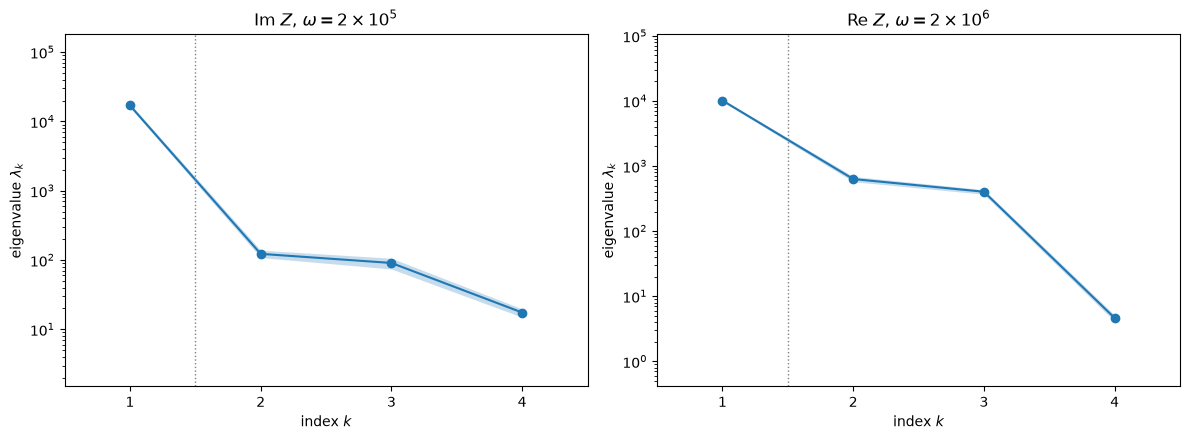

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(sub_im, ax=axes[0])
ac.plotting.plot_eigenvalues(sub_re, ax=axes[1])
axes[0].set_title(r'Im $Z$, $\omega = 2\times10^5$')
axes[1].set_title(r'Re $Z$, $\omega = 2\times10^6$')
fig.tight_layout()
plt.close(fig)
for name, s in (('Im Z(2e5)', sub_im), ('Re Z(2e6)', sub_re)):
    b = s.bootstrap_eigenvalues
    lo, hi = np.percentile(b[:, 0] / b[:, 1], [2.5, 97.5])
    print(f'{name}: bootstrap 95% interval of lambda1/lambda2 [{lo:.1f}, {hi:.1f}]')
fig

For $\mathrm{Im}\,Z(2\times10^5)$ the first eigenvalue, $1.696\times10^4$, is 138.3 times the second (bootstrap 95 % interval 123.9–152.5), and the other three (122.7, 90.6, 17.5) are close together: a one-dimensional active subspace. For $\mathrm{Re}\,Z(2\times10^6)$ the gap is smaller, $\lambda_1/\lambda_2 = 16.1$ (14.6–17.6), $\lambda_2/\lambda_3 = 1.6$, and then $\lambda_3/\lambda_4 = 87.0$: one dominant direction, two weaker ones, and one direction ($\mathbf w_4$, mostly $\tau$; next cells) along which $\mathrm{Re}\,Z$ hardly changes. The default rule (largest gap $\lambda_k - \lambda_{k+1}$) picks $n = 1$ for both, and we use $n = 1$. For $\mathrm{Im}\,Z(2\times10^5)$ that choice is clear: $\lambda_1/\lambda_2 = 138.3$ is by far the largest ratio, $\mathbf w_1$ is well determined (next subsection) and a cubic in $y_1$ fits with leave-one-out $R^2$ 0.9894 (surrogate subsection). For $\mathrm{Re}\,Z(2\times10^6)$ it is a judgement: the first eigenvalue holds most of the trace and is 16.1 times the second, but the largest *ratio* is $\lambda_3/\lambda_4 = 87.0$, which separates three directions from the nearly inactive $\mathbf w_4$; a cubic in $y_1$ reaches leave-one-out $R^2$ 0.9278 and a quadratic in $(y_1, y_2)$ 0.9653, so a second variable improves the fit, and we show both.

#### Sensitivity to the $\alpha$ cut-off

The headline gap depends on where $\alpha$ is cut. The next cell recomputes $\hat{\mathbf C}$ (same space, same normalization, no bootstrap) from the rows of the files with $\alpha$ below several cut-offs, including cut-offs above the physical limit 1 and no cut at all (all 1100 rows, $\alpha$ up to 1.617). Rows with $\alpha \ge 1$ are outside the physical range and enter only this check. Dropping rows by a cut on $\alpha$ is exact rejection sampling, so each row of the table is a Monte Carlo estimate for the lognormals restricted to that cut. The cell also prints how much of $\lambda_2$ of $\mathrm{Im}\,Z(2\times10^5)$ comes from the physical rows with $\alpha > 0.9$, and the ratios when $\ln\alpha$ is normalized by its sample sd on the physical rows instead of by $\sigma$.

In [7]:
kI, kR = k_of(2e5), k_of(2e6)
print(f"{'cut-off':>12s} {'rows':>5s} {'max alpha':>9s} | Im Z(2e5): l1/l2  l2/l3 | Re Z(2e6): l1/l2  l2/l3")
cut_table = {}
for c in (0.8, 0.9, 1.0, 1.1, 1.2, np.inf):
    r = (X[:, 2] < c) & (X[:, 1] > X[:, 0])
    Zc, Gc = np.log(X[r]), G[r] * X[r][:, None, None, :]
    rat = []
    for part, k in ((1, kI), (0, kR)):
        lam = ac.active_subspace(space=space, X=Zc, f=F[r, part, k], grads=Gc[:, part, k], estimator='as').eigenvalues
        rat += [lam[0] / lam[1], lam[1] / lam[2]]
    cut_table[c] = rat
    name = 'no cut' if np.isinf(c) else f'alpha < {c:g}'
    print(f'{name:>12s} {r.sum():5d} {X[r, 2].max():9.3f} | {rat[0]:16.1f} {rat[1]:6.2f} | {rat[2]:16.1f} {rat[3]:6.2f}')

g_im = Gl[:, 1, kI] * cm.LOG_SIGMA                # normalized gradients of Im Z(2e5), physical rows
c2 = (g_im @ sub_im.W[:, 1])**2                   # lambda2 = mean of c2
hi = Xp[:, 2] > 0.9
print(f'\nIm Z(2e5): lambda2 = {c2.mean():.2f}; the {hi.sum()} physical rows with alpha > 0.9 '
      f'({hi.mean():.1%} of the rows) contribute {c2[hi].sum() / c2.sum():.1%} of it')

sig_alt = cm.LOG_SIGMA.copy()
sig_alt[2] = Zl[:, 2].std(ddof=1)                 # ln alpha normalized by its restricted sample sd
space_alt = ac.Gaussian(cm.LOG_MU, sig_alt**2)
for name, s0, part, k in (('Im Z(2e5)', sub_im, 1, kI), ('Re Z(2e6)', sub_re, 0, kR)):
    s1 = ac.active_subspace(space=space_alt, X=Zl, f=Fp[:, part, k], grads=Gl[:, part, k], estimator='as')
    w = s1.W[:, 0] * np.sign(s1.W[:, 0] @ s0.W[:, 0])
    print(f'{name}, ln alpha scaled by its sample sd {sig_alt[2]:.4f} instead of {cm.LOG_SIGMA[2]:.4f}: '
          f'lambda1/lambda2 = {s1.eigenvalues[0] / s1.eigenvalues[1]:.1f}; largest change in a component of w1 '
          f'{np.max(np.abs(w - s0.W[:, 0])):.3f}')

     cut-off  rows max alpha | Im Z(2e5): l1/l2  l2/l3 | Re Z(2e6): l1/l2  l2/l3
 alpha < 0.8   820     0.799 |            155.1   2.73 |             21.7   1.26
 alpha < 0.9   948     0.899 |            151.0   1.88 |             18.8   1.37
   alpha < 1  1022     0.998 |            138.3   1.35 |             16.1   1.57
 alpha < 1.1  1054     1.100 |            126.3   1.15 |             15.2   1.64
 alpha < 1.2  1064     1.182 |            111.5   1.11 |             14.8   1.68
      no cut  1100     1.617 |             17.1   1.86 |             13.4   1.81

Im Z(2e5): lambda2 = 122.65; the 74 physical rows with alpha > 0.9 (7.2% of the rows) contribute 25.9% of it
Im Z(2e5), ln alpha scaled by its sample sd 0.2496 instead of 0.2936: lambda1/lambda2 = 133.3; largest change in a component of w1 0.060
Re Z(2e6), ln alpha scaled by its sample sd 0.2496 instead of 0.2936: lambda1/lambda2 = 13.8; largest change in a component of w1 0.063


| $\alpha$ cut-off | rows | $\mathrm{Im}\,Z(2\times10^5)$: $\lambda_1/\lambda_2$ | $\mathrm{Re}\,Z(2\times10^6)$: $\lambda_1/\lambda_2$ |
|---|---|---|---|
| $\alpha < 0.8$ | 820 | 155.1 | 21.7 |
| $\alpha < 0.9$ | 948 | 151.0 | 18.8 |
| $\alpha < 1$ (this notebook) | 1022 | 138.3 | 16.1 |
| $\alpha < 1.1$ | 1054 | 126.3 | 15.2 |
| $\alpha < 1.2$ | 1064 | 111.5 | 14.8 |
| no cut | 1100 | 17.1 | 13.4 |

The ratio $\lambda_1/\lambda_2$ of $\mathrm{Im}\,Z(2\times10^5)$ falls steadily as the cut moves up: from 155.1 at $\alpha < 0.8$ to 138.3 at the physical limit and 111.5 at $\alpha < 1.2$, and to 17.1 with every row. The 74 physical rows with $\alpha > 0.9$ (7.2 % of the rows) contribute 25.9 % of $\lambda_2$. **So the size of the $\mathrm{Im}\,Z$ gap is set by the upper tail of $\alpha$ near its physical limit 1**; the direction and the one-dimensional structure are not in doubt, but "138" is a property of the cut at $\alpha < 1$ as much as of the model. The cut at 1 is the paper's own physical range (p. 11), and as $\alpha \to 2$ at $\omega\tau = 1$ the denominator $1 + (i\omega\tau)^\alpha$ approaches 0, so the rows beyond it bring in near-singular gradients. $\mathrm{Re}\,Z(2\times10^6)$ depends less on the cut (21.7 to 13.4). Normalizing $\ln\alpha$ by its sample sd on the physical rows (0.2496) instead of by $\sigma$ (0.2936) gives $\lambda_1/\lambda_2$ = 133.3 and 13.8 and moves each component of $\mathbf w_1$ by at most 0.063, so the conclusions do not depend on that choice.

#### Subspace errors

Im Z(2e5): bootstrap mean subspace distance, k = 1..3: [0.005 0.133 0.034]
Re Z(2e6): bootstrap mean subspace distance, k = 1..3: [0.01  0.067 0.005]


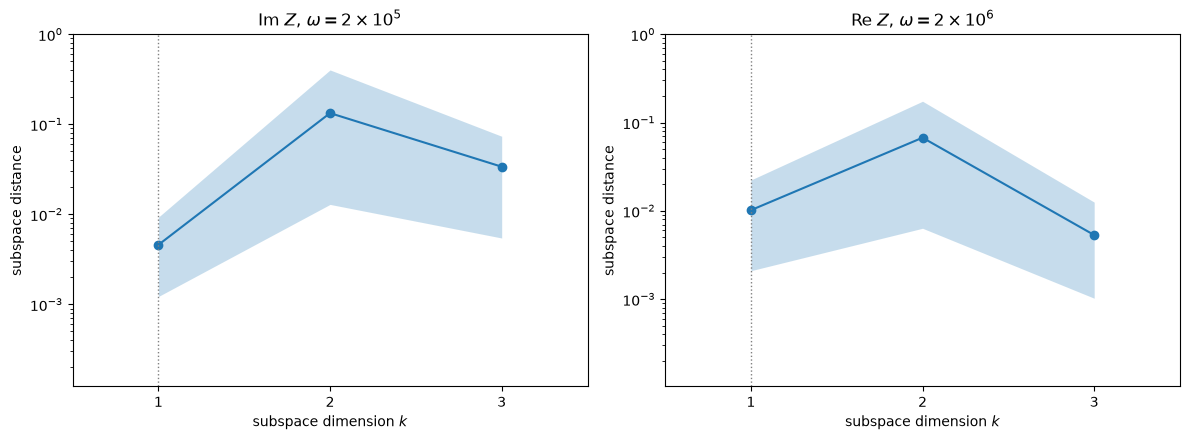

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_subspace_errors(sub_im, ax=axes[0])
ac.plotting.plot_subspace_errors(sub_re, ax=axes[1])
axes[0].set_title(r'Im $Z$, $\omega = 2\times10^5$')
axes[1].set_title(r'Re $Z$, $\omega = 2\times10^6$')
fig.tight_layout()
plt.close(fig)
for name, s in (('Im Z(2e5)', sub_im), ('Re Z(2e6)', sub_re)):
    print(f'{name}: bootstrap mean subspace distance, k = 1..3:', np.array2string(s.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance for $n = 1$ is 0.005 for $\mathrm{Im}\,Z(2\times10^5)$ and 0.01 for $\mathrm{Re}\,Z(2\times10^6)$, so $\mathbf w_1$ is well determined by the 1022 samples. For $n = 2$ the distances are 0.133 and 0.067, because $\lambda_2$ and $\lambda_3$ are close (ratios 1.4 and 1.6) and the second direction is not separated from the third.

#### Eigenvectors

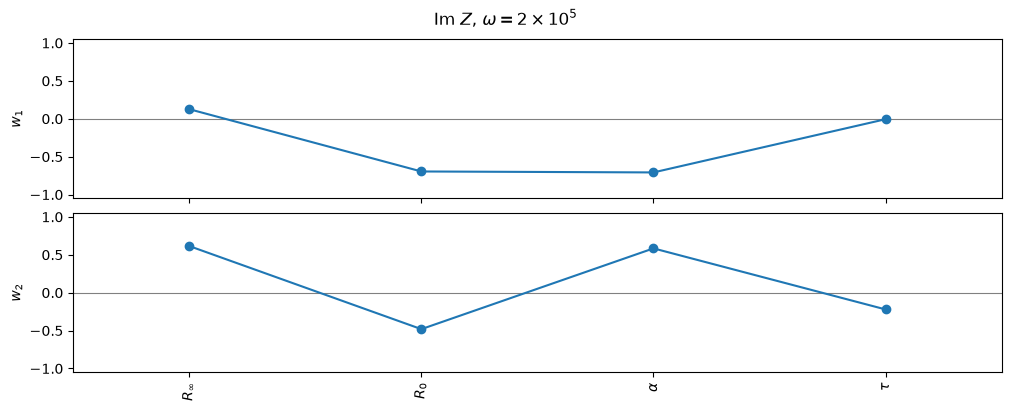

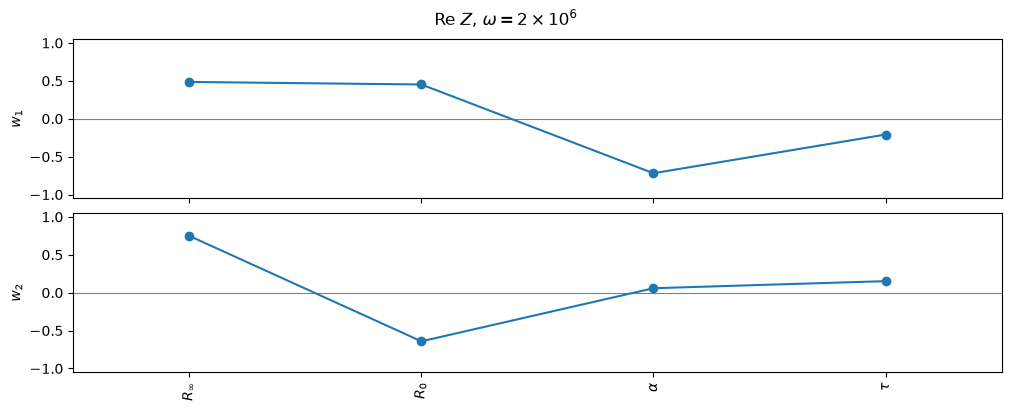

In [9]:
fig1, _ = ac.plotting.plot_eigenvectors(sub_im, indices=[0, 1], labels=labels, figsize=(10, 4))
fig1.suptitle(r'Im $Z$, $\omega = 2\times10^5$')
fig2, _ = ac.plotting.plot_eigenvectors(sub_re, indices=[0, 1], labels=labels, figsize=(10, 4))
fig2.suptitle(r'Re $Z$, $\omega = 2\times10^6$')
plt.close(fig1)
plt.close(fig2)
display(fig1)
fig2

For $\mathrm{Im}\,Z(2\times10^5)$, $\mathbf w_1$ weighs $R_0$ ($-0.695$) and $\alpha$ ($-0.708$) almost equally, $R_\infty$ a little ($+0.127$) and $\tau$ not at all ($-0.006$): $\mathrm{Im}\,Z$ is negative and grows in magnitude with $R_0$ and $\alpha$. The weight of $\tau$ vanishes because $\omega = 2\times10^5$ is $1/\bar\tau$, with $\bar\tau = 5\,\mu$s the mean of $\tau$ (Table 1; the lognormal median is $4.79\,\mu$s), and $-\mathrm{Im}\,Z$, a function of $\ln(\omega\tau)$, peaks at $\omega\tau = 1$, where its derivative with respect to $\ln\tau$ is zero. For $\mathrm{Re}\,Z(2\times10^6)$, $\mathbf w_1$ mixes $\alpha$ ($-0.718$), $R_\infty$ ($+0.486$), $R_0$ ($+0.452$) and $\tau$ ($-0.208$): here $\omega\bar\tau = 10$, so a larger $\alpha$ makes $(\omega\tau)^\alpha$ larger and the dispersion more complete, lowering $\mathrm{Re}\,Z$ towards $R_\infty$. The nearly inactive direction $\mathbf w_4$ is mostly $\tau$ ($+0.964$).

#### Sufficient summary plots

Im Z(2e5): range of f [-740.8, -28.9] ohm; corr(y1, f) = +0.953, corr(y2, f) = +0.162
Re Z(2e6): range of f [99.6, 720.5] ohm; corr(y1, f) = +0.954, corr(y2, f) = +0.065


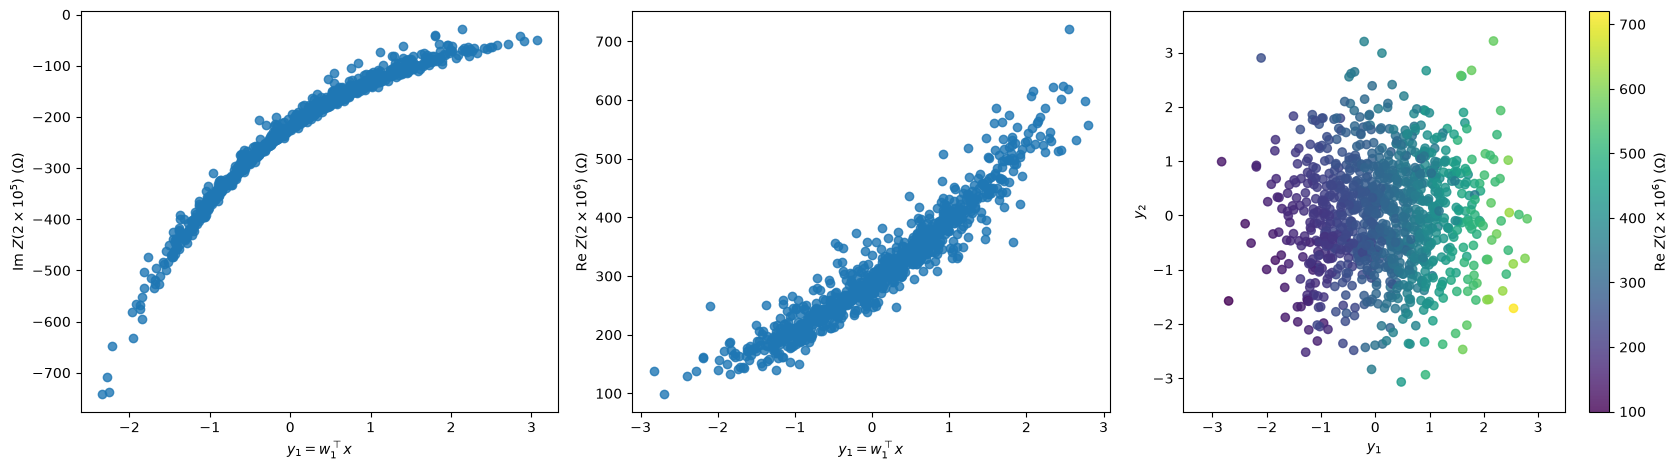

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ac.plotting.plot_sufficient_summary(sub_im, X=Zl, f=f_im, dims=1, qoi_label=r'Im $Z(2\times10^5)$ ($\Omega$)', ax=axes[0])
ac.plotting.plot_sufficient_summary(sub_re, X=Zl, f=f_re, dims=1, qoi_label=r'Re $Z(2\times10^6)$ ($\Omega$)', ax=axes[1])
sub_re2 = ac.with_dimension(sub_re, 2)
ac.plotting.plot_sufficient_summary(sub_re2, X=Zl, f=f_re, dims=2, qoi_label=r'Re $Z(2\times10^6)$ ($\Omega$)', ax=axes[2])
fig.tight_layout()
plt.close(fig)
for name, s, f in (('Im Z(2e5)', sub_im, f_im), ('Re Z(2e6)', sub_re, f_re)):
    y = space.to_normalized(Zl) @ s.W[:, :2]
    print(f'{name}: range of f [{f.min():.1f}, {f.max():.1f}] ohm; corr(y1, f) = {np.corrcoef(y[:, 0], f)[0, 1]:+.3f}, '
          f'corr(y2, f) = {np.corrcoef(y[:, 1], f)[0, 1]:+.3f}')
fig

$\mathrm{Im}\,Z(2\times10^5)$ (left, $-740.8$ to $-28.9$ $\Omega$) is a tight, curved function of $y_1$; the correlation 0.953 is below 1 because the trend is not linear. $\mathrm{Re}\,Z(2\times10^6)$ (middle, 99.6 to 720.5 $\Omega$) follows a roughly linear trend in $y_1$ (correlation 0.954) with visible scatter, and in the two-dimensional plot (right) the colour changes mainly along $y_1$ (correlation with $y_2$ 0.065).

#### Surrogates on the active variables

Polynomials in the active variables, with leave-one-out $R^2$: a cubic in $y_1$ for each quantity, and a quadratic in $(y_1, y_2)$ for $\mathrm{Re}\,Z(2\times10^6)$.

LOO R^2: Im Z(2e5) cubic in y1 0.9894; Re Z(2e6) cubic in y1 0.9278, quadratic in (y1, y2) 0.9653


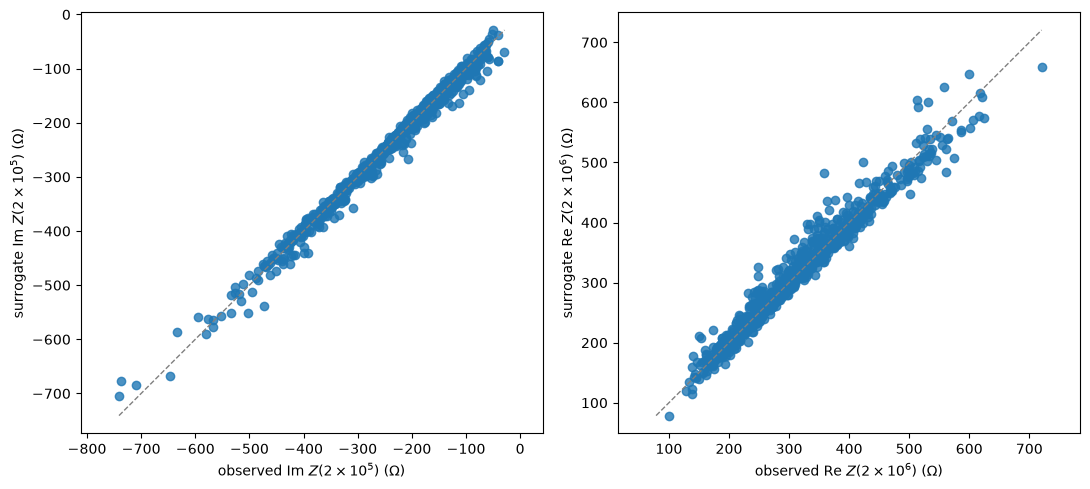

In [11]:
s_im1 = ac.fit_surrogate(X=Zl, f=f_im, subspace=sub_im, kind='poly', degree=3)
s_re1 = ac.fit_surrogate(X=Zl, f=f_re, subspace=sub_re, kind='poly', degree=3)
s_re2 = ac.fit_surrogate(X=Zl, f=f_re, subspace=sub_re2, kind='poly', degree=2)
print(f'LOO R^2: Im Z(2e5) cubic in y1 {s_im1.loo_r_squared:.4f}; Re Z(2e6) cubic in y1 {s_re1.loo_r_squared:.4f}, '
      f'quadratic in (y1, y2) {s_re2.loo_r_squared:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ac.plotting.plot_surrogate_fit(s_im1, X=Zl, f=f_im, qoi_label=r'Im $Z(2\times10^5)$ ($\Omega$)', ax=axes[0])
ac.plotting.plot_surrogate_fit(s_re2, X=Zl, f=f_re, qoi_label=r'Re $Z(2\times10^6)$ ($\Omega$)', ax=axes[1])
fig.tight_layout()
plt.close(fig)
fig

A cubic in $y_1$ reaches a leave-one-out $R^2$ of 0.9894 for $\mathrm{Im}\,Z(2\times10^5)$ and 0.9278 for $\mathrm{Re}\,Z(2\times10^6)$; a quadratic in $(y_1, y_2)$ raises the latter to 0.9653. One active variable carries most of the variation of both, and the real part at the paper's boundary frequency needs a second for a close fit.

### Extra section: the structure across frequency

The four parameters act in different frequency bands, so the active subspace changes with $\omega$. The next cell computes the subspace of $\mathrm{Re}\,Z$ and $\mathrm{Im}\,Z$ at all 31 frequencies (no bootstrap). Signs: at the lowest frequency $\mathbf w_1$ is oriented so that the quantity increases along it, and at each later frequency it is oriented to agree with the previous one, so the curves are continuous.

In [12]:
sweep = {}
for part, pname in ((0, 'Re'), (1, 'Im')):
    lam_all, W1_all, n_all, prev = [], [], [], None
    for k, w in enumerate(OMEGA):
        s = ac.active_subspace(space=space, X=Zl, f=Fp[:, part, k], grads=Gl[:, part, k], estimator='as')
        s = (ac.orient(s, by='covariance', X=Zl, f=Fp[:, part, k], columns=1) if prev is None
             else ac.orient(s, by='reference', reference=prev, columns=1))
        prev = s
        lam_all.append(s.eigenvalues); W1_all.append(s.W[:, 0]); n_all.append(s.n)
    sweep[pname] = (np.array(lam_all), np.array(W1_all), np.array(n_all))
    lam, W1, n = sweep[pname]
    print(f'{pname} Z:    omega   lambda1  l1/l2   l2/l3  n   w1 ({", ".join(cm.NAMES)})')
    for k in range(K):
        print(f'      {OMEGA[k]:9.3g} {lam[k, 0]:9.3g} {lam[k, 0] / lam[k, 1]:7.1f} {lam[k, 1] / lam[k, 2]:6.1f}  {n[k]}  '
              + ' '.join(f'{v:+.2f}' for v in W1[k]))
    r = lam[:, 0] / lam[:, 1]
    print(f'   {pname} Z: lambda1/lambda2 ranges over [{r.min():.2f}, {r.max():.3g}] (min at omega = {OMEGA[r.argmin()]:.3g}); '
          f'n = 1 at {np.sum(n == 1)} of {K} frequencies\n')

Re Z:    omega   lambda1  l1/l2   l2/l3  n   w1 (R_inf, R_0, alpha, tau)
              1  9.54e+04 10269.2 1441.5  1  +0.00 +1.00 +0.01 -0.00
           1.78  9.53e+04  7583.1 1268.4  1  +0.00 +1.00 +0.01 -0.00
           3.16  9.53e+04  5595.3 1111.0  1  +0.00 +1.00 +0.01 -0.00
           5.62  9.52e+04  4127.5  967.7  1  +0.00 +1.00 +0.01 -0.00
             10   9.5e+04  3046.0  837.4  1  +0.00 +1.00 +0.01 -0.00
           17.8  9.49e+04  2250.7  718.9  1  +0.00 +1.00 +0.02 -0.00
           31.6  9.47e+04  1666.9  611.3  1  +0.00 +1.00 +0.02 -0.00
           56.2  9.44e+04  1239.2  513.8  1  +0.00 +1.00 +0.03 -0.00
            100   9.4e+04   926.4  425.6  1  +0.00 +1.00 +0.03 -0.00
            178  9.36e+04   698.2  346.1  1  +0.00 +1.00 +0.04 -0.00
            316   9.3e+04   532.4  275.1  1  +0.00 +1.00 +0.05 -0.01
            562  9.22e+04   412.7  212.1  1  +0.00 +1.00 +0.06 -0.01
          1e+03  9.11e+04   327.8  157.1  1  +0.00 +1.00 +0.08 -0.01
       1.78e+03  8.98e+04   26

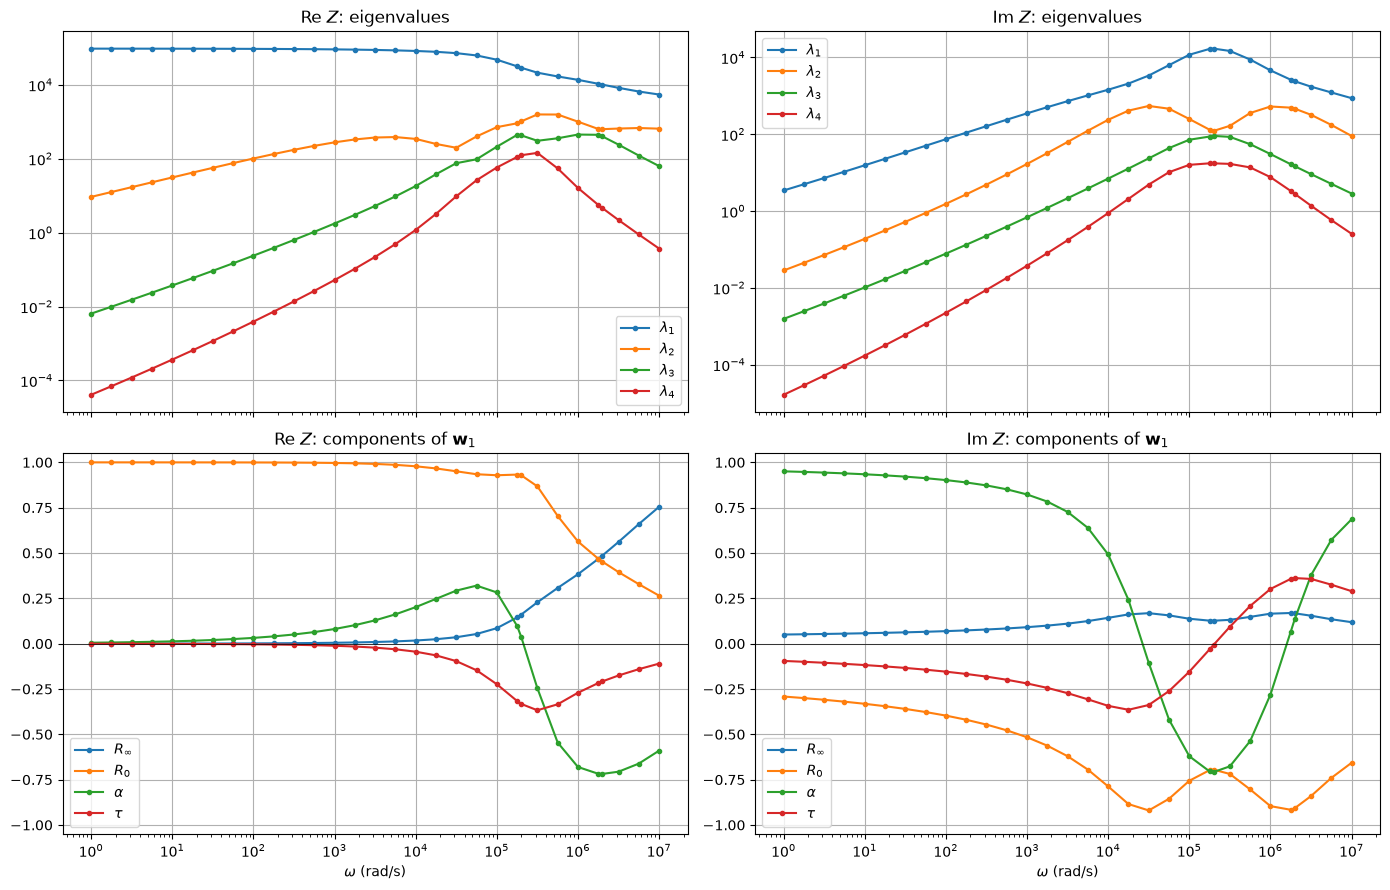

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for c, pname in enumerate(('Re', 'Im')):
    lam, W1, n = sweep[pname]
    ax = axes[0, c]
    for j in range(4):
        ax.loglog(OMEGA, lam[:, j], 'o-', ms=3, label=rf'$\lambda_{j + 1}$')
    ax.set_title(f'{pname} $Z$: eigenvalues'); ax.grid(True, which='major'); ax.legend()
    ax = axes[1, c]
    for j in range(4):
        ax.semilogx(OMEGA, W1[:, j], 'o-', ms=3, label=labels[j])
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylim(-1.05, 1.05); ax.set_title(f'{pname} $Z$: components of $\\mathbf{{w}}_1$')
    ax.set_xlabel(r'$\omega$ (rad/s)'); ax.grid(True); ax.legend()
fig.tight_layout()
plt.close(fig)
fig

**Real part.** At low frequency $\mathrm{Re}\,Z \approx R_0$: up to $\omega = 10^3$, $\mathbf w_1$ is $R_0$ (component $+1.00$; $\alpha$ at most $+0.08$) and $\lambda_1/\lambda_2$ falls from 10269 at $\omega = 1$ to 327.8 at $10^3$. Through the dispersion ($10^4$–$10^6$) the weight moves from $R_0$ to $\alpha$, $R_\infty$ and $\tau$, and at $\omega = 10^7$, $R_\infty$ leads ($+0.75$, with $\alpha$ $-0.59$) and $\lambda_1/\lambda_2$ is at its smallest, 8.4. The weight of $\alpha$ changes sign between $\omega = 2\times10^5$ ($+0.04$) and $3.16\times10^5$ ($-0.25$), near $\omega\bar\tau = 1$: below it a larger $\alpha$ makes $(\omega\tau)^\alpha$ smaller and $\mathrm{Re}\,Z$ larger, above it the reverse. **Imaginary part.** At low frequency $\alpha$ leads ($+0.95$ at $\omega = 1$; the paper's Fig. 2b also has $\alpha$ dominant there) with $\lambda_1/\lambda_2 = 121.3$; the ratio falls to its minimum, 5.07, at $\omega = 1.78\times10^4$, peaks at 138.3 at $2\times10^5$, and is 5.2–9.6 for $\omega \ge 10^6$, where $R_0$ leads up to $\omega = 5.62\times10^6$, and $\alpha$ and $R_0$ have about equal weight at $10^7$ ($+0.69$ and $-0.66$). The default rule picks $n = 1$ at all 31 frequencies for both parts, but where $\lambda_1/\lambda_2$ is near 5 the second eigenvalue is a fifth of the first.

Summary plots at three more frequencies: $\mathrm{Re}\,Z$ at $\omega = 10^3$ (low frequency), $\mathrm{Im}\,Z$ at $\omega = 10^4$ (where its $\lambda_1/\lambda_2$ is small) in two dimensions, and $\mathrm{Re}\,Z$ at $\omega = 10^7$ (high frequency).

Re Z(1e+03): lambda1/lambda2 = 327.8, lambda2/lambda3 = 157.1; w1 = R_inf +0.00, R_0 +1.00, alpha +0.08, tau -0.01; LOO R^2 of a cubic in y1 0.9989
Im Z(1e+04): lambda1/lambda2 = 6.1, lambda2/lambda3 = 34.0; w1 = R_inf +0.14, R_0 -0.79, alpha +0.49, tau -0.34; w2 = R_inf +0.11, R_0 -0.53, alpha -0.84, tau +0.06; LOO R^2 of a quadratic in (y1, y2) 0.9850
Re Z(1e+07): lambda1/lambda2 = 8.4, lambda2/lambda3 = 10.3; w1 = R_inf +0.75, R_0 +0.26, alpha -0.59, tau -0.11; LOO R^2 of a cubic in y1 0.9408


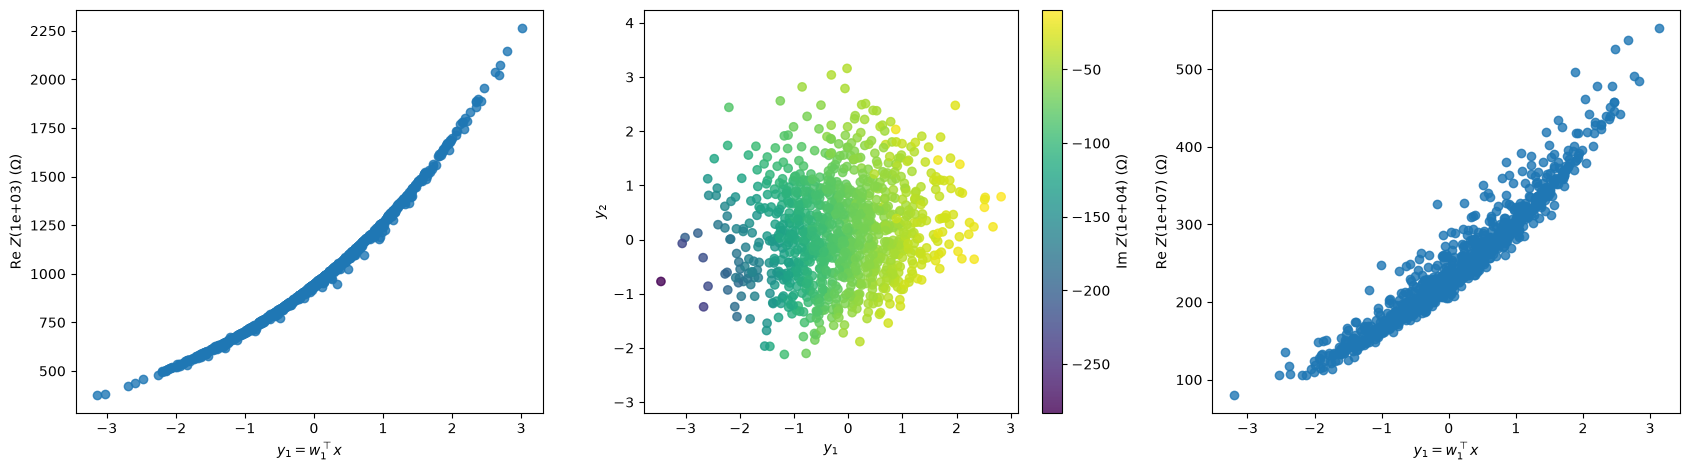

In [14]:
extra = [(0, 1e3, 1), (1, 1e4, 2), (0, 1e7, 1)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (part, w, d) in zip(axes, extra):
    s, f = subspace(part, w, nboot=0)
    s = ac.with_dimension(s, d) if d > s.n else s
    pname = ('Re', 'Im')[part]
    ac.plotting.plot_sufficient_summary(s, X=Zl, f=f, dims=d, qoi_label=f'{pname} $Z$({w:.0e}) ($\\Omega$)', ax=ax)
    lam = s.eigenvalues
    sur = ac.fit_surrogate(X=Zl, f=f, subspace=s, kind='poly', degree=3 if d == 1 else 2)
    print(f'{pname} Z({w:.0e}): lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.1f}; '
          f'w1 = ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(cm.NAMES, s.W[:, 0]))
          + (('; w2 = ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(cm.NAMES, s.W[:, 1]))) if d == 2 else '')
          + f'; LOO R^2 of a {"cubic in y1" if d == 1 else "quadratic in (y1, y2)"} {sur.loo_r_squared:.4f}')
fig.tight_layout()
plt.close(fig)
fig

At $\omega = 10^3$, $\mathrm{Re}\,Z$ is an exponential-looking curve in $y_1 \approx (\ln R_0 - \mu_{R_0})/\sigma$ ($\lambda_1/\lambda_2 = 327.8$; cubic LOO $R^2$ 0.9989), because $\mathrm{Re}\,Z \approx R_0$ there. At $\omega = 10^4$, $\mathrm{Im}\,Z$ has $\lambda_1/\lambda_2 = 6.1$ but $\lambda_2/\lambda_3 = 34.0$, so by eigenvalue ratios its active subspace is two-dimensional (the default rule, which compares differences, picks 1): $\mathbf w_1$ is mainly $R_0$ ($-0.79$) with $\alpha$ ($+0.49$) and $\tau$ ($-0.34$), $\mathbf w_2$ mainly $\alpha$ ($-0.84$) and $R_0$ ($-0.53$), and a quadratic in $(y_1, y_2)$ has LOO $R^2$ 0.9850. At $\omega = 10^7$, $\mathrm{Re}\,Z$ ($\lambda_1/\lambda_2 = 8.4$, $\lambda_2/\lambda_3 = 10.3$) follows $y_1$ with growing scatter (cubic LOO $R^2$ 0.9408).

### Extra section: the paper's Gaussian $\tau$ and the gradient estimator

Why not use Table 1's Gaussians directly? Near $\tau = 0$ the Cole term behaves like $R_0 - (R_0 - R_\infty)(i\omega\tau)^\alpha$, so $\partial Z/\partial\tau \propto \tau^{\alpha-1}$ and $(\partial Z/\partial\tau)^2 \propto \tau^{2\alpha-2}$, which is not integrable at $\tau = 0$ when $\alpha \le 1/2$. A Gaussian $\tau$ (truncated to $\tau > 0$) has a positive density at $0^+$, and the Table 1 Gaussian gives $\alpha \le 1/2$ with probability 0.17, so the $\tau$–$\tau$ entry of $\mathbf C$ is infinite under the paper's distribution, and its sample estimate does not converge. A lognormal $\tau$ has all moments of $\tau^{-p}$, so $\mathbf C$ is finite. The next cell shows this for $\mathrm{Re}\,Z(2\times10^6)$: for growing $M$ (seed `SEED`) it estimates $C_{\tau\tau}$ (normalized gradient $\sigma_\tau\,\partial Z/\partial\tau$ with the Table 1 $\sigma_\tau$ for the Gaussians; $\sigma_j\,\partial Z/\partial z_j$ for the lognormals), and prints the share of the largest single sample. Both samples are restricted to the physical domain.

In [15]:
rng = np.random.default_rng(SEED)
k2 = k_of(2e6)
print(f'Table 1 Gaussian: P(alpha <= 1/2) = {0.5 * erfc((cm.MEAN[2] - 0.5) / (cm.SD[2] * sqrt(2))):.3f}')
print('      M   Gaussian: C_tautau  largest share  min tau (us)  |  lognormal: C_tautau  largest share')
for Mg in (10**3, 10**4, 10**5, 10**6):
    Xg = cm.MEAN + cm.SD * rng.standard_normal((Mg, 4))
    Xg = Xg[cm.is_physical(Xg)]
    gg = cm.impedance_and_grad(Xg, OMEGA[k2:k2 + 1])[1][:, 0, 3].real * cm.SD[3]
    Xl = np.exp(cm.LOG_MU + cm.LOG_SIGMA * rng.standard_normal((Mg, 4)))
    Xl = Xl[cm.is_physical(Xl)]
    gl = cm.impedance_and_grad(Xl, OMEGA[k2:k2 + 1])[1][:, 0, 3].real * Xl[:, 3] * cm.LOG_SIGMA[3]
    print(f'{Mg:8d}   {np.mean(gg**2):17.4g}  {np.max(gg**2) / np.sum(gg**2):13.3f}  {Xg[:, 3].min() * 1e6:12.3g}  |  '
          f'{np.mean(gl**2):19.4g}  {np.max(gl**2) / np.sum(gl**2):13.2e}')
print(f'\nthe data set (lognormal, M = {M}): C_tautau = {np.mean((Gl[:, 0, k2, 3] * cm.LOG_SIGMA[3])**2):.4g}; '
      f'diagonal of C = {np.array2string(np.mean((Gl[:, 0, k2] * cm.LOG_SIGMA)**2, axis=0), precision=4)}')

Table 1 Gaussian: P(alpha <= 1/2) = 0.170
      M   Gaussian: C_tautau  largest share  min tau (us)  |  lognormal: C_tautau  largest share
    1000                1423          0.252         0.773  |                444.5       1.02e-02
   10000                2577          0.138         0.144  |                449.4       1.67e-03
  100000                3496          0.205      0.000106  |                449.6       1.97e-04


 1000000                4893          0.335      0.000573  |                450.6       2.71e-05

the data set (lognormal, M = 1022): C_tautau = 459.1; diagonal of C = [2829.6768 2479.5465 5411.01    459.1011]


Under the paper's Gaussians the estimate of $C_{\tau\tau}$ keeps growing with $M$ (1423, 2577, 3496, 4893 for $M = 10^3,\dots,10^6$) and a single sample carries 14–34 % of it, as samples with ever smaller $\tau$ appear (down to $1.1\times10^{-4}\,\mu$s). Under the lognormals it settles (444.5, 449.4, 449.6, 450.6), the largest single share falls like $1/M$ (from $1.0\times10^{-2}$ to $2.7\times10^{-5}$), and the data set's 1022 samples give 459.1. A gradient-based analysis under the paper's own distribution would report whatever its few smallest-$\tau$ samples happen to give; this is why the data set uses lognormals.

### Comparison with the paper

The paper reports no active subspace. Its results are the mean, standard deviation and 90 % prediction band of the impedance over frequency (Fig. 1), first-order Sobol' indices over frequency (Fig. 2) and frequency-averaged first-order and total indices (Fig. 3), computed by polynomial chaos under the Table 1 Gaussians (order and sample size not reported). To compare like with like, the next cell computes these quantities by Monte Carlo under **the paper's Gaussians**, restricted only to where the model is defined ($\alpha > 0$, $\tau > 0$; each marginal truncated separately, so the inputs stay independent; $\alpha \ge 1$ is kept, as an untruncated polynomial chaos would). Sobol' indices use the estimators of Saltelli et al. [[2]][R2] (first order, their Table 2 (b); total, Jansen's formula (f)), with 10 independent replicates of $N = 2^{13}$ base samples; we print the mean and a 95 % interval (mean $\pm 1.96$ standard errors).

In [16]:
def gauss_sample(n, rng):
    """Table 1 Gaussians, each marginal truncated to where the model is defined (alpha > 0, tau > 0)."""
    Y = cm.MEAN + cm.SD * rng.standard_normal((n, 4))
    for j in (2, 3):
        bad = Y[:, j] <= 0
        while bad.any():
            Y[bad, j] = cm.MEAN[j] + cm.SD[j] * rng.standard_normal(bad.sum())
            bad = Y[:, j] <= 0
    return Y


def sobol(n, rng, omega):
    """First-order and total Sobol' indices of Re Z and Im Z, shape (2, 4, len(omega)) each."""
    A, B = gauss_sample(n, rng), gauss_sample(n, rng)
    zA, zB = cm.impedance(A, omega), cm.impedance(B, omega)
    S, T = np.empty((2, 4, len(omega))), np.empty((2, 4, len(omega)))
    for p, part in enumerate((np.real, np.imag)):
        fA, fB = part(zA), part(zB)
        V = np.var(np.concatenate([fA, fB]), axis=0)
        for j in range(4):
            ABj = A.copy()
            ABj[:, j] = B[:, j]
            fABj = part(cm.impedance(ABj, omega))
            S[p, j] = np.mean(fB * (fABj - fA), axis=0) / V
            T[p, j] = 0.5 * np.mean((fA - fABj)**2, axis=0) / V
    return S, T


rng = np.random.default_rng(SEED)
Xmc = gauss_sample(2**16, rng)
Zmc = cm.impedance(Xmc, OMEGA)
reps = [sobol(2**13, rng, OMEGA) for _ in range(10)]
Srep, Trep = np.array([r[0] for r in reps]), np.array([r[1] for r in reps])
S, T = Srep.mean(0), Trep.mean(0)
dS, dT = 1.96 * Srep.std(0, ddof=1) / np.sqrt(10), 1.96 * Trep.std(0, ddof=1) / np.sqrt(10)
grid = np.flatnonzero(np.isclose(np.log10(OMEGA) * 4, np.round(np.log10(OMEGA) * 4)))   # the 29 points 10^(k/4)
ci = lambda v, d: f'{v:.2f} +- {d:.2f}'

re_m, re_s, im_m, im_s = Zmc.real.mean(0), Zmc.real.std(0), Zmc.imag.mean(0), Zmc.imag.std(0)
q = lambda w, p: np.percentile(Zmc.real[:, k_of(w)], p)
print(f'Gaussian MC, {len(Xmc)} samples: P(alpha >= 1) = {np.mean(Xmc[:, 2] >= 1):.3f}')
print(f'Re Z mean / sd at omega = 1: {re_m[0]:.0f} / {re_s[0]:.0f}; at 1e4: {re_m[k_of(1e4)]:.0f} / {re_s[k_of(1e4)]:.0f}; '
      f'sd at 1e5, 2e5: {re_s[k_of(1e5)]:.0f}, {re_s[k_of(2e5)]:.0f}; at 1e7: {re_m[-1]:.0f} / {re_s[-1]:.0f} ohm')
print(f'Re Z 5% / 95% quantiles at 1e4: {q(1e4, 5):.0f} / {q(1e4, 95):.0f}; at 1e7: {q(1e7, 5):.0f} / {q(1e7, 95):.0f} ohm')
kim = np.argmin(im_m)
print(f'Im Z mean: minimum {im_m[kim]:.0f} ohm at omega = {OMEGA[kim]:.3g} (grid); sd of Im Z: max {im_s.max():.0f} at omega = {OMEGA[im_s.argmax()]:.3g}')
Z2pi = cm.impedance(Xmc[:4096], 2 * np.pi * OMEGA)
print(f'Im Z 5% / 95% quantiles at 2e5: {np.percentile(Zmc.imag[:, k_of(2e5)], 5):.0f} / {np.percentile(Zmc.imag[:, k_of(2e5)], 95):.0f} ohm')
print(f'if the axis were f (omega = 2 pi f): Im Z mean minimum at axis value {OMEGA[np.argmin(Z2pi.imag.mean(0))]:.3g}')
for w in (1.0, 2e6, 1e7):
    k = k_of(w)
    print(f'first-order Sobol at omega = {w:.0e}: Re: ' + ', '.join(f'{n} {ci(S[0, j, k], dS[0, j, k])}' for j, n in enumerate(cm.NAMES))
          + ' | Im: ' + ', '.join(f'{n} {ci(S[1, j, k], dS[1, j, k])}' for j, n in enumerate(cm.NAMES)))
cross = OMEGA[np.flatnonzero(np.diff(np.sign(S[0, 0, grid] - S[0, 1, grid])))[0] + 1]
print(f'Re Z: first grid frequency with S1(R_inf) > S1(R_0): {cross:.3g}')
for p, pname in enumerate(('Re', 'Im')):
    print(f'{pname} Z: largest first-order index over frequency: R_inf {S[p, 0].max():.2f}, '
          f'tau {S[p, 3].max():.2f} at omega = {OMEGA[S[p, 3].argmax()]:.3g}')
Sa, Ta = Srep[:, :, :, grid].mean(-1), Trep[:, :, :, grid].mean(-1)       # frequency averages per replicate
for p, pname in enumerate(('Re', 'Im')):
    print(f'{pname} Z, average over the 29 log-spaced frequencies: '
          + ', '.join(f'{n} S1 {Sa[:, p, j].mean():.2f} ST {Ta[:, p, j].mean():.2f}' for j, n in enumerate(cm.NAMES))
          + f'  (95% half-widths <= {1.96 * max(Sa[:, p].std(0, ddof=1).max(), Ta[:, p].std(0, ddof=1).max()) / np.sqrt(10):.3f})')

Gaussian MC, 65536 samples: P(alpha >= 1) = 0.077
Re Z mean / sd at omega = 1: 996 / 299; at 1e4: 932 / 283; sd at 1e5, 2e5: 221, 175; at 1e7: 245 / 82 ohm
Re Z 5% / 95% quantiles at 1e4: 479 / 1406; at 1e7: 126 / 386 ohm
Im Z mean: minimum -247 ohm at omega = 2e+05 (grid); sd of Im Z: max 136 at omega = 2e+05
Im Z 5% / 95% quantiles at 2e5: -497 / -66 ohm
if the axis were f (omega = 2 pi f): Im Z mean minimum at axis value 3.16e+04
first-order Sobol at omega = 1e+00: Re: R_inf 0.00 +- 0.00, R_0 0.99 +- 0.03, alpha 0.00 +- 0.00, tau -0.00 +- 0.00 | Im: R_inf 0.00 +- 0.00, R_0 0.02 +- 0.00, alpha 0.88 +- 0.04, tau 0.00 +- 0.00
first-order Sobol at omega = 2e+06: Re: R_inf 0.24 +- 0.01, R_0 0.13 +- 0.01, alpha 0.48 +- 0.03, tau 0.07 +- 0.01 | Im: R_inf 0.03 +- 0.00, R_0 0.61 +- 0.02, alpha 0.09 +- 0.01, tau 0.18 +- 0.01
first-order Sobol at omega = 1e+07: Re: R_inf 0.47 +- 0.02, R_0 0.04 +- 0.01, alpha 0.41 +- 0.03, tau 0.02 +- 0.01 | Im: R_inf 0.02 +- 0.00, R_0 0.35 +- 0.01, alpha 0.40 

For context, the next cell compares the Sobol' indices of the paper's Gaussians with the active-subspace weights of the data set (lognormal, $\alpha<1$) at the two main frequencies. The *activity scores* $a_j = \sum_{k\le n}\lambda_k w_{jk}^2$ are the gradient-based counterpart of the total indices (they measure mean squared derivatives, not variance shares, so only their ranking is comparable).

In [17]:
for name, s, part, w in (('Im Z(2e5)', sub_im, 1, 2e5), ('Re Z(2e6)', sub_re, 0, 2e6)):
    a = np.sum(s.eigenvalues[:s.n] * s.W[:, :s.n]**2, axis=1)
    k = k_of(w)
    print(f'{name}: activity score share ' + ', '.join(f'{n} {v:.2f}' for n, v in zip(cm.NAMES, a / a.sum()))
          + ' | Gaussian total Sobol ' + ', '.join(f'{n} {T[part, j, k]:.2f}' for j, n in enumerate(cm.NAMES)))

Im Z(2e5): activity score share R_inf 0.02, R_0 0.48, alpha 0.50, tau 0.00 | Gaussian total Sobol R_inf 0.02, R_0 0.52, alpha 0.50, tau 0.02
Re Z(2e6): activity score share R_inf 0.24, R_0 0.20, alpha 0.52, tau 0.04 | Gaussian total Sobol R_inf 0.25, R_0 0.21, alpha 0.54, tau 0.08


| Quantity | Paper value | Notebook value (Table 1 Gaussians, Monte Carlo) |
|---|---|---|
| Frequency of the largest mean $\lvert\mathrm{Im}\,Z\rvert$ and of its largest s.d. | 200 kHz (p. 3); about $1.5\times10^5$ on the axis of Fig. 1b (read) | $\omega = 2\times10^5$ for both (on the grid); $3.16\times10^4$ if the axis were $f = \omega/2\pi$ |
| Mean $\mathrm{Im}\,Z$ at its peak ($\Omega$) | about $-250$ (Fig. 1b, read) | $-247$ |
| Largest s.d. of $\mathrm{Im}\,Z$ ($\Omega$) | about 150 (Fig. 1b, read) | 136 |
| 90 % band of $\mathrm{Im}\,Z$ at the peak ($\Omega$) | lower edge about $-510$ (Fig. 1b, read) | 5 %: $-497$, 95 %: $-66$ |
| Mean / s.d. of $\mathrm{Re}\,Z$ at low frequency ($\Omega$) | 1000 / about 300 (p. 3) | 996 / 299 at $\omega = 1$; 932 / 283 at $10^4$ |
| s.d. of $\mathrm{Re}\,Z$ at $10^5$, $2\times10^5$ ($\Omega$) | "around 300 from 1 Hz to 200 kHz" (p. 3); about 270 and 260 (Fig. 1a, read) | 221, 175 |
| Mean / s.d. of $\mathrm{Re}\,Z$ at $10^7$ ($\Omega$) | "approaching 300" / 100 (p. 3); about 245 / 90 (Fig. 1a, read) | 245 / 82 |
| 90 % band of $\mathrm{Re}\,Z$ at $10^4$ ($\Omega$) | 500–1500 (p. 3) | 479–1406 |
| 90 % band of $\mathrm{Re}\,Z$ at $10^7$ ($\Omega$) | 200–400 (p. 3); about 120–400 (Fig. 1a, read) | 126–386 |
| First-order indices of $\mathrm{Re}\,Z$ at $2\times10^6$: $R_\infty$, $R_0$ | 0.2, 0.19 (p. 5) | $0.24\pm0.01$, $0.13\pm0.01$ |
| Frequency where $S_{R_\infty}$ overtakes $S_{R_0}$ for $\mathrm{Re}\,Z$ | 2 MHz (p. 5) | between $5.6\times10^5$ and $10^6$ |
| First-order indices of $\mathrm{Re}\,Z$ at $10^7$: $R_\infty$, $R_0$, $\alpha$ | 0.5, 0.1, up to 0.45 (p. 4) | $0.47\pm0.02$, $0.04\pm0.01$, $0.41\pm0.03$ |
| Largest first-order index of $\tau$ over frequency | "negligible" for $\mathrm{Re}\,Z$, below 0.1 for $\mathrm{Im}\,Z$ (p. 4) | 0.20 for $\mathrm{Re}\,Z$ (at $3.16\times10^5$), 0.19 for $\mathrm{Im}\,Z$ (at $3.16\times10^6$) |
| First-order index of $\alpha$ for $\mathrm{Im}\,Z$ at $\omega = 1$ | about 0.85 (Fig. 2b, read) | $0.88\pm0.04$ |
| Frequency-averaged $S_i$ / $S_{Ti}$, $\mathrm{Re}\,Z$: $R_0$, $R_\infty$, $\alpha$, $\tau$ | 0.75/0.84, 0.05/0.12, 0.09/0.13, 0/0.02 (Fig. 3a, read) | 0.77/0.80, 0.06/0.06, 0.11/0.13, 0.03/0.04 |
| Frequency-averaged $S_i$ / $S_{Ti}$, $\mathrm{Im}\,Z$: $R_0$, $R_\infty$, $\alpha$, $\tau$ | 0.25/0.45, 0.03/0.21, 0.46/0.59, 0/0.04 (Fig. 3b, read) | 0.31/0.40, 0.01/0.02, 0.52/0.60, 0.06/0.09 |
| Active subspace | not reported | $\mathrm{Im}\,Z(2\times10^5)$: $\lambda_1/\lambda_2 = 138.3$; $\mathrm{Re}\,Z(2\times10^6)$: 16.1 (lognormal inputs, $\alpha < 1$, so $\alpha$ has mean 0.657 and sd 0.158; 155.1 and 21.7 at $\alpha < 0.8$, 111.5 and 14.8 at $\alpha < 1.2$) |

The location of the imaginary peak and the low- and high-frequency levels of $\mathrm{Re}\,Z$ agree with the paper, and they confirm that its frequency axis is $\omega$. Its text and its Fig. 1a disagree on the lower edge of the $\mathrm{Re}\,Z$ band at $10^7$ (200 against about 120 $\Omega$); our 126 agrees with the figure. Three points do not agree. (i) The s.d. of $\mathrm{Re}\,Z$ falls earlier in our computation (221 $\Omega$ at $10^5$, against about 270 read from Fig. 1a). (ii) $R_\infty$ overtakes $R_0$ between $5.6\times10^5$ and $10^6$ rather than at $2\times10^6$, where we find 0.24 and 0.13 against the paper's 0.2 and 0.19. (iii) The paper's finding that $\tau$ is negligible does not reproduce: near the dispersion $\tau$'s first-order index reaches 0.20 for $\mathrm{Re}\,Z$ and 0.19 for $\mathrm{Im}\,Z$, where the paper reports values near 0 (Fig. 2a) and below 0.1. The frequency averages agree for the dominant inputs, but the paper's large gaps between total and first-order indices, which it reads as interactions (p. 5), are mostly not reproduced: for $R_\infty$ in $\mathrm{Im}\,Z$ the paper has 0.21 against 0.03, we have 0.02 against 0.01, and our largest gap is 0.09 ($R_0$, $\mathrm{Im}\,Z$). The paper does not give its polynomial order, sample size or averaging grid, so we cannot say whether these differences come from its polynomial-chaos truncation; Monte Carlo with $10\times 6\times 2^{13}$ evaluations has the confidence intervals printed above.

The active-subspace weights of the data set rank the inputs as the total indices do at both main frequencies: for $\mathrm{Im}\,Z(2\times10^5)$ the activity-score shares are $R_0$ 0.48, $\alpha$ 0.50 (total indices 0.52, 0.50), and for $\mathrm{Re}\,Z(2\times10^6)$ $\alpha$ 0.52, $R_\infty$ 0.24, $R_0$ 0.20, $\tau$ 0.04 (total indices 0.54, 0.25, 0.21, 0.08).

### References

[1] J. Zhuang, C. Zhu, R. Han, A. Steuer, J. F. Kolb, and F. Shi. [Uncertainty quantification and sensitivity analysis for the electrical impedance spectroscopy of changes to intercellular junctions induced by cold atmospheric plasma](https://doi.org/10.3390/molecules27185861). *Molecules*, 27(18):5861, 2022.

[2] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications*, 181(2):259–270, 2010.

[3] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.3390/molecules27185861
[R2]: https://doi.org/10.1016/j.cpc.2009.09.018
[R3]: https://doi.org/10.1137/1.9781611973860

### Acknowledgments

From [[1]][R1]: "This research was funded by Basic Research Pilot Project of Suzhou (SJC2021025), and the “Hundred Talents Program” of the “Pioneer Initiative” in Chinese Academy of Sciences (Y722171202)."

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 6.7 s
